## Who worked on this part?
Muhammad Azaam Ali: compared all mushroom models on the same data, chose the final model and its threshold, scored it on the test set and analysed its mistakes.

**Aarya Ray Chaudhuri** added **Part 2** at the end of this notebook (everything from "Part 2" down) and this note. Nothing in Azaam's part above was changed. Part 2 adds two models to the comparison: the SVM from `3.4MushroomSVM.ipynb`, a kernel model that works differently from the trees and the straight line above, and the random forest we trained and tuned on AWS in `3.5MushroomSageMaker.ipynb`, the model behind our API. It compares the two with each other and with Azaam's three models on validation, on the same cross-validation folds and once on the test set, checks with a bootstrap which differences are bigger than chance, and looks at whether the models miss the same poisonous mushrooms.

This notebook needs scikit-learn 1.6.1: the saved models in `models/` were made with it, and newer versions can't load them.

# Mushroom: comparing the models

Every model notebook saved its trained pipeline in `models/`. Here we put them side by side and make the final choices:
1. **compare** all models on the validation set with the same metrics
2. **choose the threshold** of the best model, also on the validation set
3. **score the final model once on the test set**: the first time the test set is used, so the only honest estimate for new mushrooms
4. **error analysis**: which poisonous mushrooms does the final model still miss, and why?

The rule we follow: every choice (model, threshold) is made on validation. The test set only *measures* the choice; if we chose with it, its score would be too optimistic.

## Load the data and the models

In [1]:
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# walk up from where the notebook runs to the repo root, so the data path works on every machine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Mushroom' / 'datasets').is_dir())
MUSHROOM = ROOT / 'Mushroom'
DATA = MUSHROOM / 'datasets'

val_df = pd.read_csv(DATA / 'val.csv')
test_df = pd.read_csv(DATA / 'test.csv')
X_val, y_val = val_df.drop(columns='is_poisonous'), val_df['is_poisonous']
X_test, y_test = test_df.drop(columns='is_poisonous'), test_df['is_poisonous']

models = {
    'logistic regression': joblib.load(MUSHROOM / 'models' / 'logreg.pkl'),
    'random forest': joblib.load(MUSHROOM / 'models' / 'random_forest.pkl'),
    'hist gradient boosting': joblib.load(MUSHROOM / 'models' / 'hist_gradient_boosting.pkl'),
}
list(models)

['logistic regression', 'random forest', 'hist gradient boosting']

## Results from the other notebooks
PyCaret and AWS ran in other environments, so we read their saved results instead of their models.

**PyCaret** (`3.1MushroomPyCaret.ipynb`): cross-validated scores on the training data, all models with default settings. This is what made us pick the random forest and gradient boosting for tuning.

In [2]:
pycaret = pd.read_csv(MUSHROOM / 'results' / 'pycaret_leaderboard.csv', index_col=0)
pycaret[['Model', 'AUC', 'Recall', 'Prec.', 'Accuracy']].round(3)

,Model,AUC,Recall,Prec.,Accuracy
rf,Random Forest Classifier,0.831,0.601,0.804,0.793
et,Extra Trees Classifier,0.802,0.604,0.716,0.759
gbc,Gradient Boosting Classifier,0.776,0.445,0.799,0.747
knn,K Neighbors Classifier,0.751,0.528,0.712,0.740
ada,Ada Boost Classifier,0.707,0.377,0.670,0.693
lr,Logistic Regression,0.698,0.362,0.681,0.694
ridge,Ridge Classifier,0.697,0.346,0.694,0.694
lda,Linear Discriminant Analysis,0.697,0.352,0.689,0.694
dt,Decision Tree Classifier,0.672,0.589,0.594,0.692
nb,Naive Bayes,0.666,0.196,0.738,0.670


**AWS** (`3.5MushroomSageMaker.ipynb`): the tuning job on SageMaker saves its best result in `results/sagemaker_best.json`. That notebook still has to run on AWS, so the cell below only shows something once the file exists.

In [3]:
sagemaker_file = MUSHROOM / 'results' / 'sagemaker_best.json'
if sagemaker_file.exists():
    sagemaker = json.loads(sagemaker_file.read_text())
    print(sagemaker['hyperparameters'])
    print(sagemaker['metrics'])
else:
    print('not run on AWS yet: no', sagemaker_file.name)

{'_tuning_objective_metric': 'val_auc', 'max-features': '0.7986555812281954', 'min-samples-leaf': '1', 'model': '"rf"', 'n-estimators': '593', 'sagemaker_container_log_level': '20', 'sagemaker_estimator_class_name': '"SKLearn"', 'sagemaker_estimator_module': '"sagemaker.sklearn.estimator"', 'sagemaker_job_name': '"mushroom-rf-2026-10-10-21-20-30-577"', 'sagemaker_program': '"train.py"', 'sagemaker_region': '"us-east-1"', 'sagemaker_submit_directory': '"s3://sagemaker-us-east-1-349633751165/mushroom-rf-2026-10-10-21-20-30-577/source/sourcedir.tar.gz"'}
{'ObjectiveMetric': 0.8500000238418579, 'cv_auc_std': 0.02199999988079071, 'test_auc': 0.8421000242233276, 'test_precision': 0.5048999786376953, 'test_accuracy': 0.628000020980835, 'test_recall': 0.9014000296592712, 'val_precision': 0.5038999915122986, 'threshold': 0.18709999322891235, 'test_f1': 0.6473000049591064, 'val_auc': 0.8500000238418579, 'val_recall': 0.9014000296592712, 'train_auc': 1.0, 'cv_auc': 0.8263000249862671, 'test_pr_au

## Step 1: compare the models on validation
The same `evaluate()` as in the model notebooks, plus one extra metric:
- **PR-AUC** (average precision): the area under the precision-recall curve. Like ROC-AUC it doesn't depend on the threshold, but it focuses on the poisonous class: how precise can the model stay while it catches more and more poisonous mushrooms? That is exactly our trade-off.

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score, f1_score, accuracy_score

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'roc_auc': roc_auc_score(y_true, proba),
        'pr_auc': average_precision_score(y_true, proba),
        'recall': recall_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred),
        'accuracy': accuracy_score(y_true, pred),
    }

# predicted chance of poisonous for every validation mushroom, per model
val_proba = {name: model.predict_proba(X_val)[:, 1] for name, model in models.items()}

val_scores = pd.DataFrame({name: evaluate(y_val, proba) for name, proba in val_proba.items()}).T.round(3)
val_scores

,roc_auc,pr_auc,recall,precision,f1,accuracy
logistic regression,0.700,0.662,0.602,0.541,0.570,0.656
random forest,0.852,0.802,0.620,0.822,0.707,0.805
hist gradient boosting,0.829,0.786,0.577,0.770,0.660,0.775


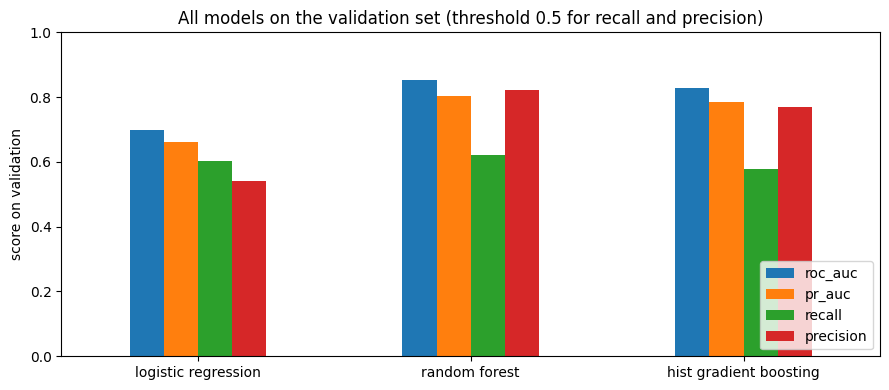

In [5]:
val_scores[['roc_auc', 'pr_auc', 'recall', 'precision']].plot.bar(figsize=(9, 4), rot=0)
plt.ylim(0, 1)
plt.ylabel('score on validation')
plt.title('All models on the validation set (threshold 0.5 for recall and precision)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The curves show the same comparison at **every** threshold at once:
- **ROC curve**: share of poisonous caught (recall) against share of edible wrongly flagged. The closer to the top-left corner, the better. The diagonal is guessing.
- **Precision-recall curve**: for every recall, how many of the flagged mushrooms are really poisonous. The dashed line is the share of poisonous mushrooms (38%): the precision you'd get by flagging at random.

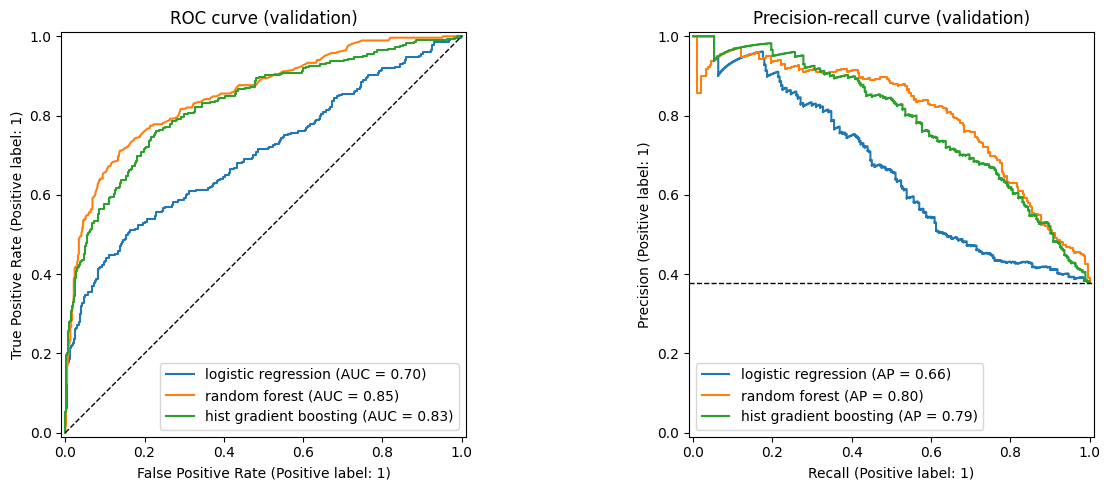

In [6]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in val_proba.items():
    RocCurveDisplay.from_predictions(y_val, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].axhline(y_val.mean(), color='k', linestyle='--', linewidth=1)
axes[0].set_title('ROC curve (validation)')
axes[1].set_title('Precision-recall curve (validation)')
plt.tight_layout()
plt.show()

### What this tells us
The **random forest** wins on every metric on validation: ROC-AUC 0.852 against 0.829 (gradient boosting) and 0.700 (logistic regression), and PR-AUC 0.802 against 0.786 and 0.662. At threshold 0.5 it also has the highest recall (0.62), precision (0.82) and accuracy (0.81).

On the curves the forest is above gradient boosting almost everywhere. Gradient boosting is only slightly ahead at the very strict end (the few mushrooms each model is most sure about, recall below about 0.35) and practically equal around recall 0.9. For the part we care about, catching most poisonous mushrooms, the forest is as good or better.

Logistic regression stays far behind on the whole curve: it can only add up one weight per feature and can't learn combinations of features, which is where the signal in this data sits.

## Step 2: choose the threshold
At threshold 0.5 the best model still calls a big part of the poisonous mushrooms edible. For a mushroom app that's the dangerous mistake, so we **fix the recall we want first** and accept the precision that comes with it.

How we pick it: `precision_recall_curve` gives precision and recall for every possible threshold. We take the **highest threshold that still catches at least the target share** of the poisonous validation mushrooms. Higher threshold = fewer edible mushrooms wrongly flagged, so the highest one that meets the target is the best one.

(`precision` and `recall` have one value more than `thresholds`, the end point of the curve, so we drop the last one with `[:-1]` to line them up.)

In [7]:
from sklearn.metrics import precision_recall_curve

final_name = val_scores['roc_auc'].idxmax()
final_model = models[final_name]
print('final model:', final_name)

precision, recall, thresholds = precision_recall_curve(y_val, val_proba[final_name])

def threshold_for(target_recall):
    return thresholds[recall[:-1] >= target_recall].max()

# what different recall targets would cost on validation
trade_off = pd.DataFrame({
    f'recall >= {target}': {'threshold': threshold_for(target), **evaluate(y_val, val_proba[final_name], threshold_for(target))}
    for target in [0.80, 0.85, 0.90, 0.95]
}).T[['threshold', 'recall', 'precision', 'accuracy']].round(3)
trade_off

final model: random forest


,threshold,recall,precision,accuracy
recall >= 0.8,0.310,0.806,0.631,0.748
recall >= 0.85,0.253,0.852,0.572,0.703
recall >= 0.9,0.197,0.901,0.512,0.637
recall >= 0.95,0.150,0.951,0.470,0.575


We choose a **recall target of 0.90**: 9 out of 10 poisonous mushrooms are flagged. This is also the default target in our deployment code (`model/train.py`), so the hosted model behaves the same way.

The plot shows the price: recall and precision against the threshold, with our choice as a vertical line.

threshold: 0.197


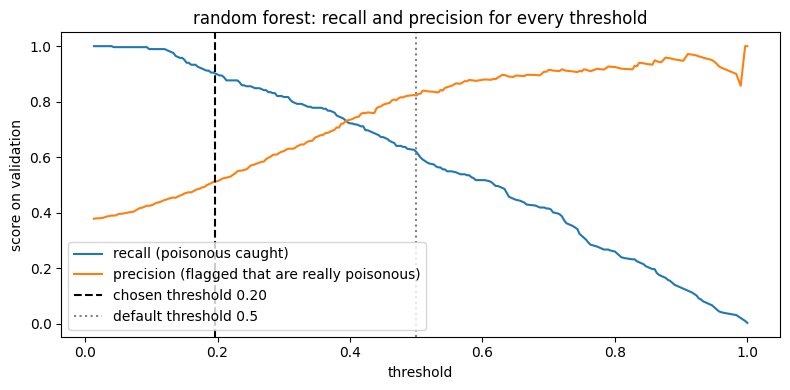

In [8]:
TARGET_RECALL = 0.90
threshold = threshold_for(TARGET_RECALL)
print('threshold:', round(threshold, 3))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, recall[:-1], label='recall (poisonous caught)')
plt.plot(thresholds, precision[:-1], label='precision (flagged that are really poisonous)')
plt.axvline(threshold, color='k', linestyle='--', label=f'chosen threshold {threshold:.2f}')
plt.axvline(0.5, color='grey', linestyle=':', label='default threshold 0.5')
plt.xlabel('threshold')
plt.ylabel('score on validation')
plt.title(f'{final_name}: recall and precision for every threshold')
plt.legend()
plt.tight_layout()
plt.show()

### What this tells us
To catch 90% of the poisonous mushrooms the threshold drops from 0.5 to 0.20. That costs a lot: precision falls from 0.82 to 0.51 and accuracy from 0.81 to 0.64. In plain words: out of every 10 mushrooms the app flags as poisonous, only about **5 really are poisonous**; the other 5 are edible mushrooms flagged to be safe.

We accept that because the two mistakes are not equally bad. Calling an edible mushroom poisonous means someone throws away a good mushroom; calling a poisonous mushroom edible can mean someone gets poisoned.

A target of 0.95 would be safer still, but the threshold would drop to 0.15 and precision to 0.47, accuracy to 0.58: more than half of the flagged mushrooms would be edible. With a model at AUC 0.85, every extra percent of recall gets more expensive. We keep 0.90, which is also the default in our deployment code.

## Step 3: the test set, once
Model and threshold are now fixed. Only now do we score on the test set, which no model and no choice has seen.

We also show the ROC-AUC of the other two models on test. That doesn't change the choice (it was made on validation); it only checks that the ranking holds on new data.

In [9]:
test_proba = final_model.predict_proba(X_test)[:, 1]

pd.DataFrame({
    f'{final_name} (val, threshold {threshold:.2f})': evaluate(y_val, val_proba[final_name], threshold),
    f'{final_name} (test, threshold {threshold:.2f})': evaluate(y_test, test_proba, threshold),
}).T.round(3)

,roc_auc,pr_auc,recall,precision,f1,accuracy
"random forest (val, threshold 0.20)",0.852,0.802,0.901,0.512,0.653,0.637
"random forest (test, threshold 0.20)",0.832,0.774,0.898,0.501,0.643,0.623


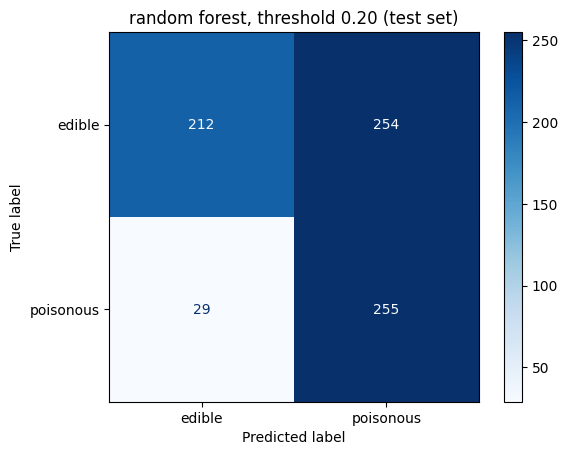

logistic regression       0.700
random forest             0.832
hist gradient boosting    0.816
Name: test roc_auc, dtype: float64

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

test_pred = (test_proba >= threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['edible', 'poisonous'], cmap='Blues')
plt.title(f'{final_name}, threshold {threshold:.2f} (test set)')
plt.show()

# does the ranking of the models hold on new data?
pd.Series({name: roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]) for name, model in models.items()}, name='test roc_auc').round(3)

### What this tells us
The test scores are close to validation: ROC-AUC 0.832 against 0.852, accuracy 0.62 against 0.64. A small drop is normal, because the model and threshold were chosen on validation, so validation is slightly optimistic. The test set is the honest number.

Test recall is 0.898: just under the 0.90 target (255 of the 284 poisonous test mushrooms caught, 29 missed). The threshold was chosen on only 284 poisonous validation mushrooms, so one or two mushrooms more or less above the line change the recall by almost 0.01. On new rows it moves a little, which is why a target is never a hard guarantee.

The model ranking holds on test: random forest 0.832, gradient boosting 0.816, logistic regression 0.700.

## Step 4: error analysis
Which poisonous mushrooms does the final model still call edible (**false negatives**)? We sort every test mushroom into the four outcomes of the confusion matrix and compare the groups.

Ideas from the EDA and cleaning to check:
- **missing values**: are the missed ones the mushrooms with the most gaps (`n_missing`)?
- **size**: do they look like the typical edible mushroom?
- **the suspicious groups**: stemless mushrooms (almost all poisonous) and giant caps above 40 cm (almost all edible), where we found likely flipped labels

In [11]:
errors = X_test.copy()
errors['is_poisonous'] = y_test.values
errors['proba'] = test_proba
errors['n_missing'] = (X_test == 'missing').sum(axis=1)  # empty categories, filled with 'missing' in cleaning
errors['stemless'] = errors['stem_surface'] == 'f'
errors['giant'] = errors['cap_diameter_cm'] > 40

real = errors['is_poisonous'] == 1
flagged = test_pred == 1
errors['outcome'] = np.select(
    [real & ~flagged, real & flagged, ~real & flagged],
    ['missed poisonous (FN)', 'caught poisonous (TP)', 'edible flagged (FP)'],
    default='edible correct (TN)',
)

errors.groupby('outcome').agg(
    mushrooms=('proba', 'size'),
    mean_proba=('proba', 'mean'),
    n_missing=('n_missing', 'mean'),
    cap_diameter_cm=('cap_diameter_cm', 'mean'),
    stem_width_mm=('stem_width_mm', 'mean'),
    share_stemless=('stemless', 'mean'),
    share_giant=('giant', 'mean'),
).round(2)

,mushrooms,mean_proba,n_missing,cap_diameter_cm,stem_width_mm,share_stemless,share_giant
outcome,,,,,,,
caught poisonous (TP),255,0.62,2.39,5.56,10.32,0.04,0.0
edible correct (TN),212,0.12,2.38,7.38,15.08,0.00,0.0
edible flagged (FP),254,0.36,2.50,6.48,12.26,0.00,0.0
missed poisonous (FN),29,0.11,2.38,8.90,15.91,0.00,0.0


The missed poisonous mushrooms themselves, lowest predicted chance first: the ones the model was most sure were edible.

In [12]:
missed = errors[errors['outcome'] == 'missed poisonous (FN)'].sort_values('proba')
missed[['proba', 'n_missing', 'cap_diameter_cm', 'stem_width_mm', 'stem_surface', 'cap_shape', 'ring_type', 'gill_color']].round(2)

,proba,n_missing,cap_diameter_cm,stem_width_mm,stem_surface,cap_shape,ring_type,gill_color
511,0.01,2,5.60,9.10,s,f,f,missing
458,0.02,3,8.29,16.66,s,x,f,missing
616,0.03,1,6.16,5.51,t,x,l,n
193,0.03,2,8.40,16.97,s,f,f,w
541,0.06,3,8.37,16.43,missing,f,f,missing
570,0.06,2,6.32,11.17,s,f,e,w
627,0.06,3,17.65,22.79,missing,f,f,k
219,0.08,1,6.54,13.02,s,x,f,y
585,0.09,2,7.16,13.21,missing,x,f,r
689,0.09,2,8.73,18.12,y,p,p,missing


### What this tells us
- **Not the gaps.** The 29 missed poisonous mushrooms have on average 2.4 empty categories, the same as the edible mushrooms the model got right (2.4) and the caught poisonous ones (2.4).
- **Not the suspicious groups.** None of them is stemless or has a giant cap.
- **They look like edible mushrooms.** Their average cap (8.9 cm) and stem width (15.9 mm) are close to the correctly classified edible ones (7.4 cm, 15.1 mm) and far from the caught poisonous ones (5.6 cm, 10.3 mm). The model is very sure they are edible: their average predicted chance is 0.11, about the same as for the real edible ones (0.12), against 0.62 for the caught poisonous ones.

So these are poisonous mushrooms that look edible in every column the dataset has. Some are probably **flipped labels** (edible mushrooms labelled poisonous, as the assignment warns); others are species that are poisonous but simply can't be told apart from edible ones with these 10 features. No model can catch those: there is nothing in the data that separates them, and a model that did "catch" them on training data would only be memorising.

## Conclusion
The final model is the **random forest** (tuned in `3.2MushroomRandomForest.ipynb`): it has the best ROC-AUC and PR-AUC on validation, it is as good or better than gradient boosting on the part of the curves we care about, and the ranking holds on test.

With the threshold set to catch 90% of the poisonous validation mushrooms (0.20), it scores on the **test set**: ROC-AUC 0.832, recall 0.898, precision 0.50, accuracy 0.62. About half of the mushrooms it flags are really edible. We accept that because missing a poisonous mushroom is far worse than throwing away an edible one.

The 29 poisonous test mushrooms it still misses don't have more gaps and aren't in the stemless or giant groups: they look like edible mushrooms in every feature, and the model is confident they are edible. Part of them are likely flipped labels, part are poisonous species these features can't separate.

What could still help: more rows, and features the dataset lost (the original UCI data had more columns and no gaps). What can't be fixed is the label noise: with flipped labels in train and test, no model can reach a perfect score, and tuning has already stopped giving real gains for all three models (every improvement was within the noise between folds).

# Part 2 (Aarya Ray Chaudhuri): the SVM and the SageMaker forest
Everything above is Azaam's comparison of his three models. This part adds two more and compares all five. The rules stay the same: every choice is made on validation or cross-validation, and the test set only measures.

An update to the AWS result in "Results from the other notebooks" above: its saved output shows our first tuning run (593 trees). We ran the tuning again in a new lab account, and the model behind the API is now the best forest of that second run (308 trees, `min_samples_leaf=2`, `max_features=0.77`). `results/sagemaker_best.json` holds that run, and Part 2 uses it.

What Part 2 answers:
1. Can we rebuild the SageMaker forest here, and is it the same model as on AWS?
2. Are the five models compared on the same footing?
3. How do the five compare on validation?
4. Are the differences bigger than chance?
5. How do they do on the test set?
6. Do they miss the same poisonous mushrooms?
7. What does each one cost to store and to run?

## 2.1 Load the SVM and rebuild the SageMaker forest
The SVM is saved in `models/svm.pkl`, like Azaam's models.

The SageMaker forest is saved in the S3 bucket of our lab account, which this notebook can't read. But we have everything to train it again: the exact code that ran on AWS (`model/`), its settings (`results/sagemaker_best.json`) and the same split. It works the way it does on AWS: it reads the raw csv, `prepare()` does the cleaning steps, and the imputer sits inside the pipeline. So it gets its own copy of the split from `split()`. We check that this copy holds the same mushrooms in the same order as Azaam's files, by comparing the categories (which nobody imputed) and the labels.

In [13]:
import sys
import math
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

sys.path.insert(0, str(MUSHROOM / 'model'))
from mushroom_model import build_pipeline, prepare, split

svm = joblib.load(MUSHROOM / 'models' / 'svm.pkl')

train_df = pd.read_csv(DATA / 'train.csv')
X_train, y_train = train_df.drop(columns='is_poisonous'), train_df['is_poisonous']
cat_cols = [c for c in X_train.columns if X_train[c].dtype == object]

# the sagemaker forest starts from the raw csv, like on AWS
raw = pd.read_csv(DATA / 'mushroom_project_dataset.csv')
Xr_train, Xr_val, Xr_test, yr_train, yr_val, yr_test = split(prepare(raw), (raw['class'] == 'p').astype(int))
for part, (a, b, ya, yb) in {'train': (Xr_train, X_train, yr_train, y_train), 'val': (Xr_val, X_val, yr_val, y_val), 'test': (Xr_test, X_test, yr_test, y_test)}.items():
    print(part, 'same mushrooms as the csv:', (a[cat_cols].to_numpy() == b[cat_cols].to_numpy()).all() and (ya.to_numpy() == yb.to_numpy()).all())

sagemaker_best = json.loads((MUSHROOM / 'results' / 'sagemaker_best.json').read_text())
hp = sagemaker_best['hyperparameters']
sm_params = {'n_estimators': int(hp['n-estimators']), 'min_samples_leaf': int(hp['min-samples-leaf']), 'max_features': float(hp['max-features'])}
sm_forest = build_pipeline('rf', **sm_params).fit(Xr_train, yr_train)
sm_params

train same mushrooms as the csv: True
val same mushrooms as the csv: True
test same mushrooms as the csv: True


{'n_estimators': 308,
 'min_samples_leaf': 2,
 'max_features': 0.7703161969145527}

All three parts of the split hold the same mushrooms in the same order as Azaam's files, so all five models are trained and scored on the same rows. The forest gets the settings of the second tuning run: 308 trees, leaves of at least 2 mushrooms, and 77% of the columns to choose from at every split.

**Is it the same model as on AWS?** The tuning job saved its own validation numbers. We compute the same ones for the rebuilt forest, with the same threshold rule as `model/train.py`: the highest threshold that still catches 90% of the poisonous validation mushrooms, rounded down to 4 decimals.

In [14]:
sm_val_proba = sm_forest.predict_proba(Xr_val)[:, 1]
p, r, t = precision_recall_curve(y_val, sm_val_proba)
sm_threshold = math.floor(t[r[:-1] >= 0.90].max() * 10000) / 10000  # the same rule as model/train.py
rebuilt = evaluate(y_val, sm_val_proba, sm_threshold)
aws = sagemaker_best['metrics']

print('hosted model on AWS, refit on train + validation: test AUC', round(aws['test_auc'], 3), 'recall', round(aws['test_recall'], 3), 'precision', round(aws['test_precision'], 3))
pd.DataFrame({
    'AWS job': {'val_auc': aws['val_auc'], 'threshold': aws['threshold'], 'val_recall': aws['val_recall'], 'val_precision': aws['val_precision']},
    'rebuilt here': {'val_auc': rebuilt['roc_auc'], 'threshold': sm_threshold, 'val_recall': rebuilt['recall'], 'val_precision': rebuilt['precision']},
}).round(4)

hosted model on AWS, refit on train + validation: test AUC 0.84 recall 0.915 precision 0.502


,AWS job,rebuilt here
val_auc,0.8499,0.8499
threshold,0.1838,0.1838
val_recall,0.9014,0.9014
val_precision,0.4812,0.4812


The rebuilt forest gives exactly the AWS job's validation numbers: AUC 0.8499, threshold 0.1838, recall 0.9014, precision 0.4812. The same code, rows and `random_state` give the same forest, here with scikit-learn 1.6.1 and on AWS with 1.9.0.

The model behind the API is this forest trained once more on train + validation (4250 rows) after the threshold was chosen, which is how `model/train.py` works. On AWS that version scored test AUC 0.84, recall 0.915 and precision 0.502. For a fair comparison we use the version trained on the same 3500 training rows as the other four models.

## 2.2 Are the five models compared on the same footing?
All five use the same mushrooms, but not the same version of them. Azaam's models and the SVM learn from his files, cut from `mushroom_clean.csv`. There the missing measurements were filled in by an imputer that saw all 5000 rows, test rows included: no labels, but still a small leak (the note in notebook 2). The SageMaker forest fills them in itself, inside its pipeline, from the training rows only.

If that difference mattered, comparing the SageMaker forest with the others would partly compare data preparation instead of models. So we train the SageMaker settings on both versions of the same rows, with the same 5 folds as Azaam (`StratifiedKFold`, `random_state=42`).

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # the same folds as in Azaam's notebooks
sm_on_clean = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)], remainder='passthrough')),
    ('rf', RandomForestClassifier(**sm_params, random_state=42, n_jobs=-1)),
])
footing = pd.DataFrame({
    'raw csv, imputer learns from the training folds': cross_val_score(build_pipeline('rf', **sm_params), Xr_train, yr_train, cv=cv, scoring='roc_auc'),
    'clean csv, imputed with all 5000 rows': cross_val_score(sm_on_clean, X_train, y_train, cv=cv, scoring='roc_auc'),
}, index=[f'fold {i + 1}' for i in range(5)])
footing['difference'] = footing.iloc[:, 1] - footing.iloc[:, 0]
footing.loc['mean'] = footing.mean()
footing.round(3)

,"raw csv, imputer learns from the training folds","clean csv, imputed with all 5000 rows",difference
fold 1,0.854,0.845,-0.008
fold 2,0.820,0.816,-0.003
fold 3,0.828,0.826,-0.002
fold 4,0.793,0.792,-0.000
fold 5,0.838,0.841,0.003
mean,0.826,0.824,-0.002


### What this tells us
The two versions of the data give the same forest: mean cross-validated AUC 0.826 on the raw csv and 0.824 on the clean csv, a difference of −0.002, and per fold between −0.008 and +0.003, far inside the spread between folds. The leak in `mushroom_clean.csv` gives a model no advantage, so comparing the SageMaker forest with the other four is fair.

This also answers a question from the Story of `3.5MushroomSageMaker.ipynb`: the AWS cross-validation (0.827) was lower than notebook 2's (0.840), and one suspect was the imputer. It isn't the imputer. What's left is the other change: notebook 2 cross-validated on all 5000 rows, the AWS job only on the 3500 training rows (not tested here).

## 2.3 All five models on validation
Two kinds of numbers:
- **ROC-AUC and PR-AUC** don't depend on a threshold, so they compare the models directly.
- **At 90% recall:** like in Azaam's Step 2, every model gets the highest threshold that still catches 90% of the poisonous validation mushrooms. Each model needs its own threshold, because each puts its probabilities on its own scale. The precision and accuracy at that threshold show what catching 9 out of 10 poisonous mushrooms costs with each model.

We also compute the test probabilities of all five here, for later.

In [16]:
val_proba_all = {**val_proba, 'svm': svm.predict_proba(X_val)[:, 1], 'sagemaker forest': sm_val_proba}
test_proba_all = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
test_proba_all['svm'] = svm.predict_proba(X_test)[:, 1]
test_proba_all['sagemaker forest'] = sm_forest.predict_proba(Xr_test)[:, 1]

def threshold_at(y_true, proba, target_recall=0.90):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    return thresholds[recall[:-1] >= target_recall].max()

thresholds_90 = {name: threshold_at(y_val, proba) for name, proba in val_proba_all.items()}
val_table = pd.DataFrame({name: {'threshold': thresholds_90[name], **evaluate(y_val, proba, thresholds_90[name])} for name, proba in val_proba_all.items()}).T
val_table[['roc_auc', 'pr_auc', 'threshold', 'recall', 'precision', 'accuracy']].round(3)

,roc_auc,pr_auc,threshold,recall,precision,accuracy
logistic regression,0.700,0.662,0.315,0.901,0.418,0.488
random forest,0.852,0.802,0.197,0.901,0.512,0.637
hist gradient boosting,0.829,0.786,0.145,0.901,0.521,0.649
svm,0.821,0.763,0.171,0.901,0.490,0.608
sagemaker forest,0.850,0.809,0.184,0.901,0.481,0.595


### What this tells us
- **The two forests lead**: ROC-AUC 0.852 (Azaam's) and 0.850 (SageMaker), PR-AUC 0.802 and 0.809. Then gradient boosting (0.829), the SVM (0.821) and, far behind, logistic regression (0.700).
- **The SVM sits between logistic regression and the trees**: +0.12 AUC over logistic regression with exactly the same input, but about 0.03 below the forests.
- **At 90% recall the four non-linear models are close**: precision between 0.481 and 0.521, against 0.418 for logistic regression. Gradient boosting has the highest precision there (0.521) and the SageMaker forest the lowest of the four (0.481), although their AUCs rank them the other way round. That precision is measured at one single point of the curve, where a few mushrooms more or less above the threshold move it a lot, so the AUC is the better guide to rank the models.

The same curves as in Azaam's Step 1, now with all five models.

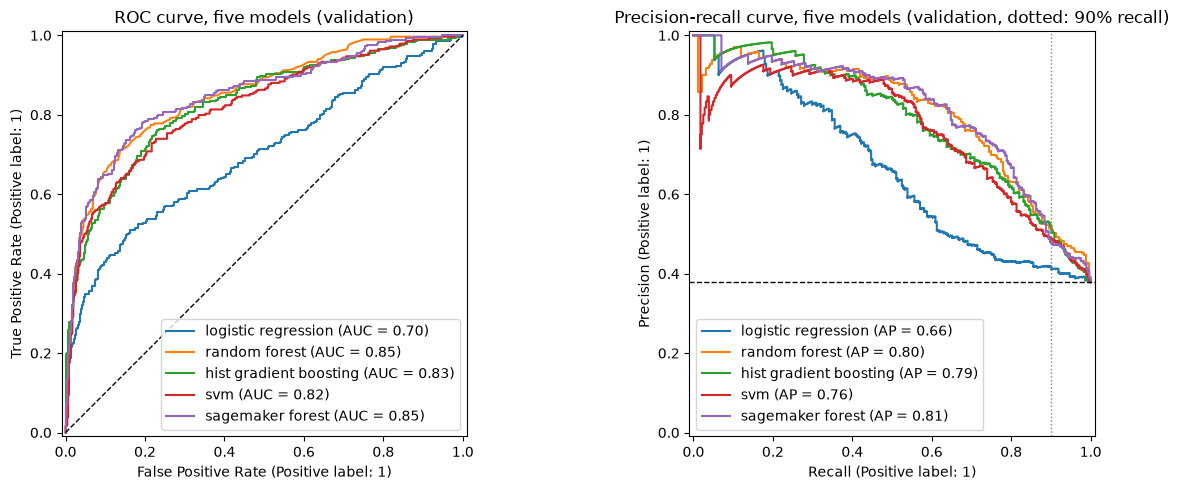

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in val_proba_all.items():
    RocCurveDisplay.from_predictions(y_val, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].axhline(y_val.mean(), color='k', linestyle='--', linewidth=1)
axes[1].axvline(0.9, color='grey', linestyle=':', linewidth=1)
axes[0].set_title('ROC curve, five models (validation)')
axes[1].set_title('Precision-recall curve, five models (validation, dotted: 90% recall)')
plt.tight_layout()
plt.show()

On the curves the two forests lie on top of each other almost everywhere. The SVM's ROC curve runs just below gradient boosting's for most of the range. On the precision-recall curve the SVM is weakest at the start: among the mushrooms it is most sure about there are some edible ones, so its precision dips at low recall where the other models stay close to 1. The curves come closer as recall goes up, and at the dotted 90% line the four non-linear models are all between about 0.48 and 0.52.

## 2.4 Are the differences bigger than chance?
A difference of 0.01 AUC can come from which mushrooms happen to be in the validation set. Two checks:

**1. Cross-validation on the same 5 folds.** Every model's settings are trained again on each set of 4 folds and scored on the 5th (`clone` copies the settings, not the trained model). For Azaam's three models this repeats his own cross-validation, so his numbers should come back. The SageMaker forest's scores come from 2.2, on its own inputs (the raw csv) and the same folds. Standard deviation as in `GridSearchCV` (`ddof=0`).

In [18]:
cv_scores = {name: cross_val_score(clone(model), X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1) for name, model in models.items()}
cv_scores['svm'] = cross_val_score(clone(svm), X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_scores['sagemaker forest'] = footing.iloc[:5, 0].to_numpy()

cv_table = pd.DataFrame(cv_scores, index=[f'fold {i + 1}' for i in range(5)])
cv_summary = pd.DataFrame({'mean': cv_table.mean(), 'std': cv_table.std(ddof=0)}).T
pd.concat([cv_table, cv_summary]).round(3)

,logistic regression,random forest,hist gradient boosting,svm,sagemaker forest
fold 1,0.717,0.850,0.833,0.797,0.854
fold 2,0.680,0.825,0.812,0.801,0.820
fold 3,0.703,0.833,0.838,0.817,0.828
fold 4,0.717,0.806,0.798,0.811,0.793
fold 5,0.692,0.847,0.828,0.811,0.838
mean,0.702,0.832,0.822,0.807,0.826
std,0.014,0.016,0.015,0.007,0.020


The pairs we care about, fold by fold: the two new models against each other, each against Azaam's forest, and the SVM against the two other non-forest models.

In [19]:
pairs = [
    ('sagemaker forest', 'random forest'),
    ('svm', 'sagemaker forest'),
    ('svm', 'random forest'),
    ('svm', 'hist gradient boosting'),
    ('svm', 'logistic regression'),
    ('hist gradient boosting', 'random forest'),
]
wins = pd.DataFrame({f'{a} vs {b}': {
    'mean difference': (cv_table[a] - cv_table[b]).mean(),
    'folds where the first wins': (cv_table[a] > cv_table[b]).sum(),
} for a, b in pairs}).T
wins['folds where the first wins'] = wins['folds where the first wins'].astype(int)
wins.round(3)

,mean difference,folds where the first wins
sagemaker forest vs random forest,-0.006,1
svm vs sagemaker forest,-0.019,1
svm vs random forest,-0.025,1
svm vs hist gradient boosting,-0.015,1
svm vs logistic regression,0.106,5
hist gradient boosting vs random forest,-0.010,1


### What this tells us
Azaam's three models get back exactly the cross-validation scores of his own notebooks (0.702, 0.832, 0.822), so this is the same measurement.
- **SageMaker forest against Azaam's forest**: 0.826 against 0.832, and the SageMaker forest wins only 1 of the 5 folds. The mean difference (−0.006) is smaller than the spread between folds of either forest (0.016 and 0.020).
- **SVM against the forests**: the SVM loses 4 of 5 folds against each, by 0.025 (Azaam's forest) and 0.019 (SageMaker) on average. It only wins fold 4, where both forests score their lowest (0.806 and 0.793).
- **SVM against the other two**: below gradient boosting in 4 of 5 folds (−0.015 on average), above logistic regression in all 5 (+0.106).
- The SVM's score moves least from fold to fold (standard deviation 0.007, against 0.014 to 0.020 for the others), which fits its smooth boundary.

**2. A paired bootstrap on validation.** We draw 750 mushrooms from the 750 validation mushrooms *with replacement* (bootstrapping, from the slides), score every model on that same sample, and repeat 2000 times. The middle 95% of the 2000 differences is the range the difference could have had with a different validation set. If that range doesn't contain 0, the difference is bigger than chance. "Paired" means both models are always scored on the same sample, so how easy a sample is cancels out.

In [20]:
def bootstrap_differences(y_true, probas, pairs, rounds=2000):
    y = np.asarray(y_true)
    rng = np.random.default_rng(42)
    samples = [rng.integers(0, len(y), len(y)) for _ in range(rounds)]
    aucs = {name: np.array([roc_auc_score(y[s], proba[s]) for s in samples]) for name, proba in probas.items()}
    return pd.DataFrame({f'{a} - {b}': {
        'AUC difference': roc_auc_score(y, probas[a]) - roc_auc_score(y, probas[b]),
        'low (2.5%)': np.percentile(aucs[a] - aucs[b], 2.5),
        'high (97.5%)': np.percentile(aucs[a] - aucs[b], 97.5),
    } for a, b in pairs}).T

bootstrap_differences(y_val, val_proba_all, pairs).round(3)

,AUC difference,low (2.5%),high (97.5%)
sagemaker forest - random forest,-0.002,-0.011,0.006
svm - sagemaker forest,-0.029,-0.050,-0.007
svm - random forest,-0.031,-0.051,-0.011
svm - hist gradient boosting,-0.008,-0.032,0.017
svm - logistic regression,0.121,0.083,0.157
hist gradient boosting - random forest,-0.023,-0.039,-0.007


### What this tells us
The "low" and "high" columns are the 95% range of each difference.
- **SageMaker forest − Azaam's forest: −0.002, range −0.011 to +0.006.** 0 is inside, so on validation the two forests can't be told apart.
- **SVM − each forest: about −0.03, ranges up to −0.007 and −0.011.** 0 is outside, so both forests really are better than the SVM.
- **SVM − gradient boosting: −0.008, range −0.032 to +0.017.** Can't be told apart.
- **SVM − logistic regression: +0.121, range +0.083 to +0.157.** Clearly better.
- **Gradient boosting − Azaam's forest: −0.023, range −0.039 to −0.007.** This backs up Azaam's choice of the forest over boosting with a test against chance.

## 2.5 The test set, once
Every model keeps the threshold it got on validation in 2.3; nothing is chosen here. Azaam already scored his three models on test in Step 3; we add the SVM and the SageMaker forest, and count how many poisonous test mushrooms each model calls edible.

In [21]:
test_table = pd.DataFrame({name: {
    **evaluate(y_test, proba, thresholds_90[name]),
    'missed poisonous': int(((proba < thresholds_90[name]) & (y_test == 1)).sum()),
} for name, proba in test_proba_all.items()}).T
test_table[['roc_auc', 'pr_auc', 'recall', 'precision', 'accuracy', 'missed poisonous']].round(3)

,roc_auc,pr_auc,recall,precision,accuracy,missed poisonous
logistic regression,0.700,0.653,0.912,0.419,0.488,25.0
random forest,0.832,0.774,0.898,0.501,0.623,29.0
hist gradient boosting,0.816,0.754,0.891,0.504,0.627,31.0
svm,0.807,0.745,0.870,0.483,0.599,37.0
sagemaker forest,0.833,0.778,0.905,0.490,0.607,27.0


### What this tells us
On test the order is the same as on validation: the forests first (ROC-AUC 0.833 SageMaker, 0.832 Azaam's), then gradient boosting (0.816), the SVM (0.807) and logistic regression (0.700).

With the thresholds from validation:
- The SageMaker forest misses the fewest poisonous mushrooms of the four non-linear models (27, recall 0.905), the SVM the most (37, recall 0.870): its threshold carried over worst from validation to test.
- Precision lies between 0.483 and 0.504 for those four: whichever we take, about half of the flagged mushrooms are edible.
- Logistic regression misses only 25, but by flagging far more mushrooms: precision 0.419 and accuracy 0.488.

The SageMaker forest trained on 3500 rows scores test AUC 0.833 here. The hosted version, trained on 4250 rows, scored 0.84 on AWS (2.1).

The same bootstrap on the 750 test mushrooms, to see if the conclusions from validation hold on data no choice was made on.

In [22]:
bootstrap_differences(y_test, test_proba_all, pairs).round(3)

,AUC difference,low (2.5%),high (97.5%)
sagemaker forest - random forest,0.001,-0.007,0.009
svm - sagemaker forest,-0.026,-0.051,-0.002
svm - random forest,-0.025,-0.049,-0.003
svm - hist gradient boosting,-0.010,-0.036,0.017
svm - logistic regression,0.107,0.071,0.144
hist gradient boosting - random forest,-0.016,-0.030,-0.002


The test set confirms validation: the two forests can't be told apart (+0.001, range −0.007 to +0.009). The SVM is below both (about −0.025, ranges ending at −0.002 and −0.003, so just clear of 0), level with gradient boosting (−0.010, range −0.036 to +0.017) and far above logistic regression (+0.107). Gradient boosting stays below Azaam's forest (−0.016, range −0.030 to −0.002).

## 2.6 Do they miss the same poisonous mushrooms?
Azaam's error analysis found that the forest's missed poisonous mushrooms look edible in every column. If that is a property of the data, a model built in a completely different way should miss the same ones.

The table counts, for every pair of models, the poisonous test mushrooms that **both** call edible (each at its own threshold from 2.3). On the diagonal: how many that model misses in total.

In [23]:
missed = {name: set(np.where((proba < thresholds_90[name]) & (y_test.to_numpy() == 1))[0]) for name, proba in test_proba_all.items()}
print('missed by all five models:', len(set.intersection(*missed.values())))
print('missed by all three tree models:', len(missed['random forest'] & missed['hist gradient boosting'] & missed['sagemaker forest']))
pd.DataFrame({a: {b: len(missed[a] & missed[b]) for b in missed} for a in missed})

missed by all five models: 2
missed by all three tree models: 22


,logistic regression,random forest,hist gradient boosting,svm,sagemaker forest
logistic regression,25,6,6,7,5
random forest,6,29,23,15,25
hist gradient boosting,6,23,31,14,24
svm,7,15,14,37,13
sagemaker forest,5,25,24,13,27


### What this tells us
- **The tree models miss the same mushrooms.** The two forests share 25 of their 27 and 29 misses, and 22 are missed by all three tree models.
- **The SVM misses other ones.** Only 15 of its 37 misses are also missed by Azaam's forest. So the SVM catches 14 of the forest's 29 misses, and misses 22 mushrooms the forest catches.
- **Logistic regression is different again**: it shares only 5 to 7 misses with each of the other models.
- **Only 2 poisonous mushrooms are missed by all five models.**

This corrects part of the error analysis in Step 4 above. The forest's missed mushrooms do look edible *to tree models*: all three miss nearly the same ones. But they aren't invisible to every model: the SVM catches 14 of the forest's 29, and logistic regression 23 of them (while flagging far more edible mushrooms). Different kinds of models draw the line at different mushrooms. What stays true is that no model catches them without missing others or flagging more edible ones.

A second view, without any threshold: how similarly do the models **rank** the test mushrooms? Spearman correlation of their predicted chances: 1 means the same order, 0 means no relation.

In [24]:
pd.DataFrame(test_proba_all).corr(method='spearman').round(2)

,logistic regression,random forest,hist gradient boosting,svm,sagemaker forest
logistic regression,1.00,0.52,0.54,0.50,0.54
random forest,0.52,1.00,0.91,0.82,0.97
hist gradient boosting,0.54,0.91,1.00,0.75,0.92
svm,0.50,0.82,0.75,1.00,0.79
sagemaker forest,0.54,0.97,0.92,0.79,1.00


The rankings tell the same story without any threshold: the two forests order the test mushrooms almost identically (0.97), gradient boosting is close to them (0.91 and 0.92), the SVM less so (0.75 to 0.82), and logistic regression orders them very differently (0.50 to 0.54).

**Would combining the forest and the SVM help?** If the SVM catches some of the mushrooms the forest misses, the average of their two predicted chances might be better than either one (an ensemble). We only check this on **validation**: picking a combination because of its test score would be using the test set to choose.

In [25]:
pd.Series({
    'random forest': roc_auc_score(y_val, val_proba_all['random forest']),
    'svm': roc_auc_score(y_val, val_proba_all['svm']),
    'average of the two': roc_auc_score(y_val, (val_proba_all['random forest'] + val_proba_all['svm']) / 2),
}, name='validation roc_auc').round(4)

random forest         0.8523
svm                   0.8213
average of the two    0.8471
Name: validation roc_auc, dtype: float64

No: the average of the forest and the SVM scores 0.847 on validation, below the forest alone (0.852). The SVM catches other mushrooms, but it is a weaker model overall (0.821), and averaging with it costs the forest more than it gains. So we don't build a combined model.

## 2.7 Size and speed
What each model costs to store (the saved file, compressed like Azaam's) and to run: the time to predict all 750 test mushrooms on a laptop, the fastest of 5 runs. Speeds change a little between runs, so only the order and the size of the differences matter.

In [26]:
import io
import time

costs = {}
for name, model in {**models, 'svm': svm, 'sagemaker forest': sm_forest}.items():
    X = Xr_test if name == 'sagemaker forest' else X_test
    buffer = io.BytesIO()
    joblib.dump(model, buffer, compress=3)
    runs = []
    for _ in range(5):
        start = time.perf_counter()
        model.predict_proba(X)
        runs.append(time.perf_counter() - start)
    costs[name] = {'file size (MB)': len(buffer.getvalue()) / 1e6, 'predict 750 mushrooms (ms)': min(runs) * 1000}
pd.DataFrame(costs).T.round(2)

,file size (MB),predict 750 mushrooms (ms)
logistic regression,0.00,2.97
random forest,6.22,39.81
hist gradient boosting,1.13,12.61
svm,0.10,76.40
sagemaker forest,4.76,52.05


### What this tells us
- **Size**: the SVM is the smallest of the non-linear models (0.10 MB): it only stores its 2494 support vectors. The forests are the biggest (about 4.8 and 6.2 MB), hundreds of trees with every split in them.
- **Speed**: the SVM is the slowest to predict, because it compares every mushroom with all its support vectors. The two forests come next, gradient boosting is faster than both, and logistic regression is almost instant.
- For our API this doesn't matter: it gets one mushroom per request, and even the SVM needs less than 100 ms for all 750 mushrooms, about 0.1 ms per mushroom. The choice of model can rest on how well it predicts.

## Conclusion of Part 2
**The SageMaker forest and Azaam's forest are equally good.** Different settings (308 trees, leaves of at least 2, 77% of the columns per split, against 300 trees, leaves of 1, 30% of the columns) and different data preparation (the raw csv with its own imputer, against the clean csv), but the same results: cross-validated 0.826 against 0.832 (1 of 5 folds won), validation 0.850 against 0.852, test 0.833 against 0.832, and both bootstrap ranges contain 0. They also miss almost the same poisonous mushrooms (25 shared) and rank the test mushrooms almost identically (0.97). So the model behind our API is as good as the best model in this comparison, and we keep it.

**The SVM is a real step up from logistic regression, but not from the trees.** With exactly the same input it gains 0.11 to 0.12 AUC over logistic regression (in all 5 folds, on validation and on test): a boundary that can bend is what the linear model was missing. Against both forests it loses 0.02 to 0.03 AUC in cross-validation, on validation and on test, with bootstrap ranges below 0. It is level with gradient boosting. In `3.4MushroomSVM.ipynb` it used the same five columns as the forest but got less out of stem width, the likely reason the trees stay ahead.

**The SVM against the SageMaker forest, head to head:** the forest is better at what matters, predicting: AUC in cross-validation 0.826 against 0.807, on validation 0.850 against 0.821, on test 0.833 against 0.807, and on test it misses 27 poisonous mushrooms against 37. The SVM is smaller (0.10 MB against 4.76 MB) and its score moves least between folds (0.007), but it is slower to predict and only gives probabilities through the extra Platt scaling step.

**What the comparison changes in the error analysis above:** the forest's missed poisonous mushrooms are hard for tree models, not for every model. The SVM catches 14 of the forest's 29 and logistic regression 23, and only 2 are missed by all five. But no model catches them without missing others or flagging more edible mushrooms, and averaging the forest with the SVM made validation AUC worse (0.847 against 0.852). So Azaam's conclusion that these features won't take us much further still holds, but "no model can catch them" is too strong: the models put the line in different places.

**The ranking:** the two forests, then gradient boosting and the SVM, then logistic regression. The differences that are bigger than chance on both validation and test: logistic regression against every other model, the SVM against both forests, and gradient boosting against Azaam's forest. Between the two forests, and between the SVM and gradient boosting, there is no real difference. We keep the SageMaker forest behind the API.